# 03 — Classical ML: Logistic Regression and XGBoost
5-fold stratified CV on training data for every model x imbalance technique. Precision / recall / F1 here are at the default 0.5 threshold; the real threshold is chosen by cost later. **Judge by PR-AUC.**

Stop rule: if 2-3 more experiments improve PR-AUC by less than 0.01, stop.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import PrecisionRecallDisplay
from sklearn.model_selection import cross_val_predict

from src import config
from src.preprocess import load_data, train_test
from src.train import build_pipeline, cv_compare, cv_splitter

df = load_data(verbose=False)
X_train, X_test, y_train, y_test = train_test(df)  # X_test stays untouched
pos_weight = float((y_train == 0).sum() / (y_train == 1).sum())

## Cross-validated comparison

In [2]:
results_path = config.RESULTS_DIR / "cv_results_lr_xgb.csv"
config.RESULTS_DIR.mkdir(parents=True, exist_ok=True)
results = cv_compare(X_train, y_train, models=("lr", "xgb"), results_path=results_path)

  lr | none         | PR-AUC 0.7527 ± 0.0312 | recall 0.614 | precision 0.868 | 5.3s


  lr | class_weight | PR-AUC 0.7544 ± 0.0265 | recall 0.918 | precision 0.060 | 7.9s


  lr | undersample  | PR-AUC 0.6024 ± 0.1157 | recall 0.913 | precision 0.044 | 2.4s


  File "D:\Credit Card Fraud Detection\.venv\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\Gulab Ahmad\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\Gulab Ahmad\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\Gulab Ahmad\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


  lr | smote        | PR-AUC 0.7522 ± 0.0269 | recall 0.907 | precision 0.057 | 15.0s


 xgb | none         | PR-AUC 0.8480 ± 0.0265 | recall 0.791 | precision 0.943 | 33.3s


 xgb | class_weight | PR-AUC 0.8421 ± 0.0290 | recall 0.831 | precision 0.879 | 32.9s


 xgb | undersample  | PR-AUC 0.7317 ± 0.0760 | recall 0.907 | precision 0.048 | 6.6s


 xgb | smote        | PR-AUC 0.8346 ± 0.0365 | recall 0.839 | precision 0.591 | 54.9s


In [3]:
def fmt(r, k):
    return f"{r[k + '_mean']:.3f} ± {r[k + '_std']:.3f}"

table = pd.DataFrame({
    "model": results.model, "technique": results.technique,
    "PR-AUC": [fmt(r, "pr_auc") for _, r in results.iterrows()],
    "Recall@0.5": [fmt(r, "recall") for _, r in results.iterrows()],
    "Precision@0.5": [fmt(r, "precision") for _, r in results.iterrows()],
    "F1@0.5": [fmt(r, "f1") for _, r in results.iterrows()],
    "ROC-AUC": [fmt(r, "roc_auc") for _, r in results.iterrows()],
    "train PR-AUC": results.train_pr_auc.round(3),
    "sec": results.seconds,
}).sort_values("PR-AUC", ascending=False)
table

,model,technique,PR-AUC,Recall@0.5,Precision@0.5,F1@0.5,ROC-AUC,train PR-AUC,sec
4,xgb,none,0.848 ± 0.026,0.791 ± 0.062,0.943 ± 0.030,0.858 ± 0.030,0.983 ± 0.005,1.000,33.3
5,xgb,class_weight,0.842 ± 0.029,0.831 ± 0.044,0.879 ± 0.037,0.853 ± 0.029,0.979 ± 0.006,1.000,32.9
7,xgb,smote,0.835 ± 0.036,0.839 ± 0.042,0.591 ± 0.026,0.693 ± 0.023,0.976 ± 0.007,0.996,54.9
1,lr,class_weight,0.754 ± 0.026,0.918 ± 0.025,0.060 ± 0.007,0.113 ± 0.012,0.981 ± 0.008,0.757,7.9
0,lr,none,0.753 ± 0.031,0.614 ± 0.055,0.868 ± 0.022,0.717 ± 0.033,0.976 ± 0.014,0.766,5.3
3,lr,smote,0.752 ± 0.027,0.907 ± 0.034,0.057 ± 0.006,0.107 ± 0.011,0.981 ± 0.008,0.756,15.0
6,xgb,undersample,0.732 ± 0.076,0.907 ± 0.032,0.048 ± 0.004,0.091 ± 0.007,0.980 ± 0.008,0.767,6.6
2,lr,undersample,0.602 ± 0.116,0.913 ± 0.025,0.044 ± 0.006,0.084 ± 0.010,0.981 ± 0.008,0.581,2.4


## Did XGBoost really beat the baseline?

In [4]:
best = results.loc[results.groupby("model").pr_auc_mean.idxmax()].set_index("model")
gain = best.loc["xgb", "pr_auc_mean"] - best.loc["lr", "pr_auc_mean"]
print(f"Best LR : {best.loc['lr', 'technique']:<12} PR-AUC {best.loc['lr', 'pr_auc_mean']:.4f}")
print(f"Best XGB: {best.loc['xgb', 'technique']:<12} PR-AUC {best.loc['xgb', 'pr_auc_mean']:.4f}")
print(f"Gain over LR baseline: {gain:+.4f} -> {'real improvement' if gain >= config.MIN_PR_AUC_GAIN else 'not meaningful'}")
gap = best.loc["xgb", "train_pr_auc"] - best.loc["xgb", "pr_auc_mean"]
print(f"XGB train vs CV PR-AUC gap: {gap:.3f} ({'overfitting risk' if gap > 0.1 else 'acceptable'})")

Best LR : class_weight PR-AUC 0.7544
Best XGB: none         PR-AUC 0.8480
Gain over LR baseline: +0.0936 -> real improvement
XGB train vs CV PR-AUC gap: 0.152 (overfitting risk)


## Precision–recall curves (out-of-fold predictions on training data)

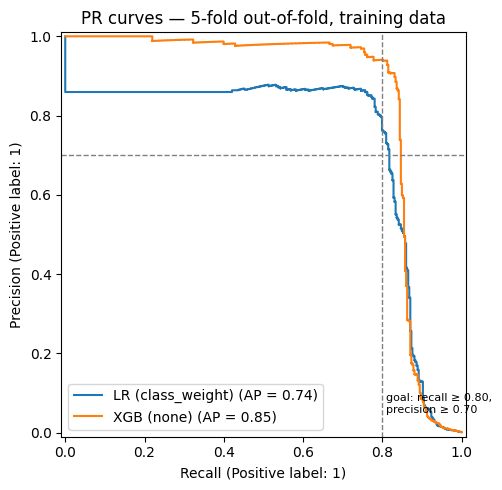

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
oof = {}
for name in ["lr", "xgb"]:
    tech = best.loc[name, "technique"]
    proba = cross_val_predict(build_pipeline(name, tech, pos_weight), X_train, y_train,
                              cv=cv_splitter(), method="predict_proba")[:, 1]
    oof[name] = proba
    PrecisionRecallDisplay.from_predictions(y_train, proba, ax=ax, name=f"{name.upper()} ({tech})")
ax.axhline(config.TARGET_PRECISION, ls="--", c="grey", lw=1)
ax.axvline(config.TARGET_RECALL, ls="--", c="grey", lw=1)
ax.text(config.TARGET_RECALL + 0.01, 0.05, "goal: recall ≥ 0.80,\nprecision ≥ 0.70", fontsize=8)
ax.set_title("PR curves — 5-fold out-of-fold, training data")
fig.tight_layout(); fig.savefig(config.FIGURES_DIR / "03_pr_curves_lr_xgb.png", dpi=150); plt.show()

## Can each model reach the business goal at some threshold?

In [6]:
import numpy as np
from sklearn.metrics import precision_recall_curve

for name, proba in oof.items():
    p, r, t = precision_recall_curve(y_train, proba)
    ok = (r[:-1] >= config.TARGET_RECALL) & (p[:-1] >= config.TARGET_PRECISION)
    if ok.any():
        i = np.where(ok)[0][np.argmax(p[:-1][ok])]
        print(f"{name.upper()}: goal reachable, e.g. threshold {t[i]:.6f} -> precision {p[i]:.3f}, recall {r[i]:.3f}")
    else:
        i = np.argmin(np.abs(r[:-1] - config.TARGET_RECALL))
        print(f"{name.upper()}: goal NOT reachable; at recall {r[i]:.3f} precision is only {p[i]:.3f}")

pd.DataFrame({"y": y_train.values, "amount": X_train["Amount"].values, **{f"oof_{k}": v for k, v in oof.items()}}) \
  .to_csv(config.RESULTS_DIR / "oof_lr_xgb.csv", index=False)

LR: goal reachable, e.g. threshold 0.999919 -> precision 0.763, recall 0.802
XGB: goal reachable, e.g. threshold 0.466227 -> precision 0.941, recall 0.802
